# Analysis: learned AST pruning for token-budgeted code context

Everything here is computed from the per-issue result files in `results/runs/`.
Run all cells to rebuild the tables in `results/summary/` and `results/tables/` and the figures in `results/figures/`.
No GPU and no dataset download are needed.

In [1]:
import json, subprocess, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
def run(*args):
    out = subprocess.run([sys.executable, *args], cwd=ROOT, capture_output=True, text=True)
    print(out.stdout[-1500:] or out.stderr[-1500:])
pd.set_option("display.width", 200)

## 1. Rebuild summaries, tables and figures from the per-issue rows

In [2]:
for split in ("dev", "lite", "verified"):
    run("experiments/summarize.py", "--split", split, "--quiet")
    run("experiments/make_tables.py", "--split", split)
run("experiments/make_figures.py", "--split", "lite")
run("experiments/make_figures.py", "--split", "verified")

wrote results/tables/dev_oracle_imports_main.md and .tex (9 rows)
wrote results/tables/dev_oracle_main.md and .tex (9 rows)
wrote results/tables/dev_bm25_5_main.md and .tex (9 rows)
wrote results/tables/dev_settings.md and .tex (9 rows)
wrote results/tables/dev_oracle_imports_paired.md and .tex (36 rows)
wrote results/tables/dev_bm25_5_paired.md and .tex (36 rows)
wrote results/tables/dev_oracle_imports_ablation.md and .tex (12 rows)



wrote results/tables/lite_oracle_imports_main.md and .tex (11 rows)
wrote results/tables/lite_oracle_main.md and .tex (11 rows)
wrote results/tables/lite_bm25_5_main.md and .tex (9 rows)
wrote results/tables/lite_settings.md and .tex (11 rows)
wrote results/tables/lite_oracle_imports_paired.md and .tex (48 rows)
wrote results/tables/lite_bm25_5_paired.md and .tex (36 rows)
wrote results/tables/lite_oracle_imports_ablation.md and .tex (9 rows)
wrote results/tables/lite_external.md and .tex (8 rows)
wrote results/tables/lite_downstream_qwen7b_4bit.md and .tex (5 rows)
wrote results/tables/lite_seeds.md and .tex (5 rows)



wrote results/tables/verified_oracle_imports_main.md and .tex (9 rows)
wrote results/tables/verified_oracle_main.md and .tex (9 rows)
wrote results/tables/verified_bm25_5_main.md and .tex (9 rows)
wrote results/tables/verified_settings.md and .tex (9 rows)
wrote results/tables/verified_oracle_imports_paired.md and .tex (36 rows)
wrote results/tables/verified_bm25_5_paired.md and .tex (36 rows)
wrote results/tables/verified_oracle_imports_ablation.md and .tex (9 rows)



wrote results/figures/lite_recall_vs_budget.png
wrote results/figures/lite_line_recall_vs_budget.png
wrote results/figures/lite_paired_differences.png
wrote results/figures/lite_scaling.png
wrote results/figures/training_dev_recall.png
wrote results/figures/error_categories.png



wrote results/figures/verified_recall_vs_budget.png
wrote results/figures/verified_line_recall_vs_budget.png
wrote results/figures/verified_paired_differences.png
wrote results/figures/training_dev_recall.png
wrote results/figures/error_categories.png



## 2. Main result: SWE-bench Lite, gold files plus direct imports

Gold-function recall with 95% bootstrap intervals and other metrics, in percent. lite, gold files + direct imports, 274 issues with a gold function.

| Method | Recall @10% | Recall @25% | Recall @50% | Line recall @25% | All-gold @25% | Sig. recall @25% | Precision @25% | Parses @25% |
|---|---|---|---|---|---|---|---|---|
| Line window | 4.8 [2.6, 7.4] | 17.2 [13.0, 21.7] | 43.1 [37.4, 48.8] | 25.0 | 16.1 | 26.6 | 2.1 | 39.4 |
| Chunk RAG (BM25) | 36.5 [30.9, 42.3] | 55.5 [49.7, 61.2] | 80.3 [75.5, 84.9] | 77.7 | 54.0 | 74.3 | 6.0 | 12.4 |
| Chunk RAG (UniXcoder, zero-shot) | 22.4 [17.7, 27.4] | 46.8 [41.1, 52.5] | 69.8 [64.4, 75.0] | 69.6 | 44.9 | 65.3 | 5.1 | 13.1 |
| Skeleton (Agentless-style) | 1.1 [0.0, 2.6] | 6.8 [4.0, 9.9] | 35.9 [30.3, 41.6] | 9.7 | 6.6 | 97.8 | 0.9 | 100.0 |
| SWE-Pruner (released checkpoint) | 32.0 [26.6, 37.7] | 54.6 [48.7, 60.3] | 81.0 [76.3, 85.6] | 87.6 | 53.3 | 80.3 | 6.7 | 14.7 |
| AST + random order | 9.3 [6.0, 12.8] | 20.7 [16.2, 25.3] | 44.5 [38.9, 50.1] | 21.1 | 18.2 | 23.2 | 1.2 | 100.0 |
| AST + BM25 | 60.9 [55.2, 66.5] | 77.1 [72.2, 81.8] | 90.7 [87.2, 94.0] | 76.2 | 74.5 | 81.5 | 6.5 | 100.0 |
| AST + UniXcoder, zero-shot | 46.6 [40.9, 52.4] | 64.0 [58.3, 69.5] | 83.5 [79.0, 87.6] | 66.2 | 61.7 | 68.8 | 4.8 | 100.0 |
| AST + LLM perplexity | 70.3 [64.9, 75.5] | 82.1 [77.6, 86.5] | 90.0 [86.3, 93.2] | 78.9 | 81.4 | 83.6 | 5.6 | 100.0 |
| AST + trained ranker (ours) | 81.8 [77.2, 86.1] | 94.3 [91.6, 96.9] | 98.0 [96.4, 99.3] | 87.8 | 93.8 | 95.4 | 7.1 | 100.0 |
| AST + trained ranker + BM25 (ours) | 79.6 [74.8, 84.3] | 92.9 [89.8, 95.8] | 97.6 [95.6, 99.3] | 87.0 | 92.3 | 93.6 | 7.0 | 100.0 |


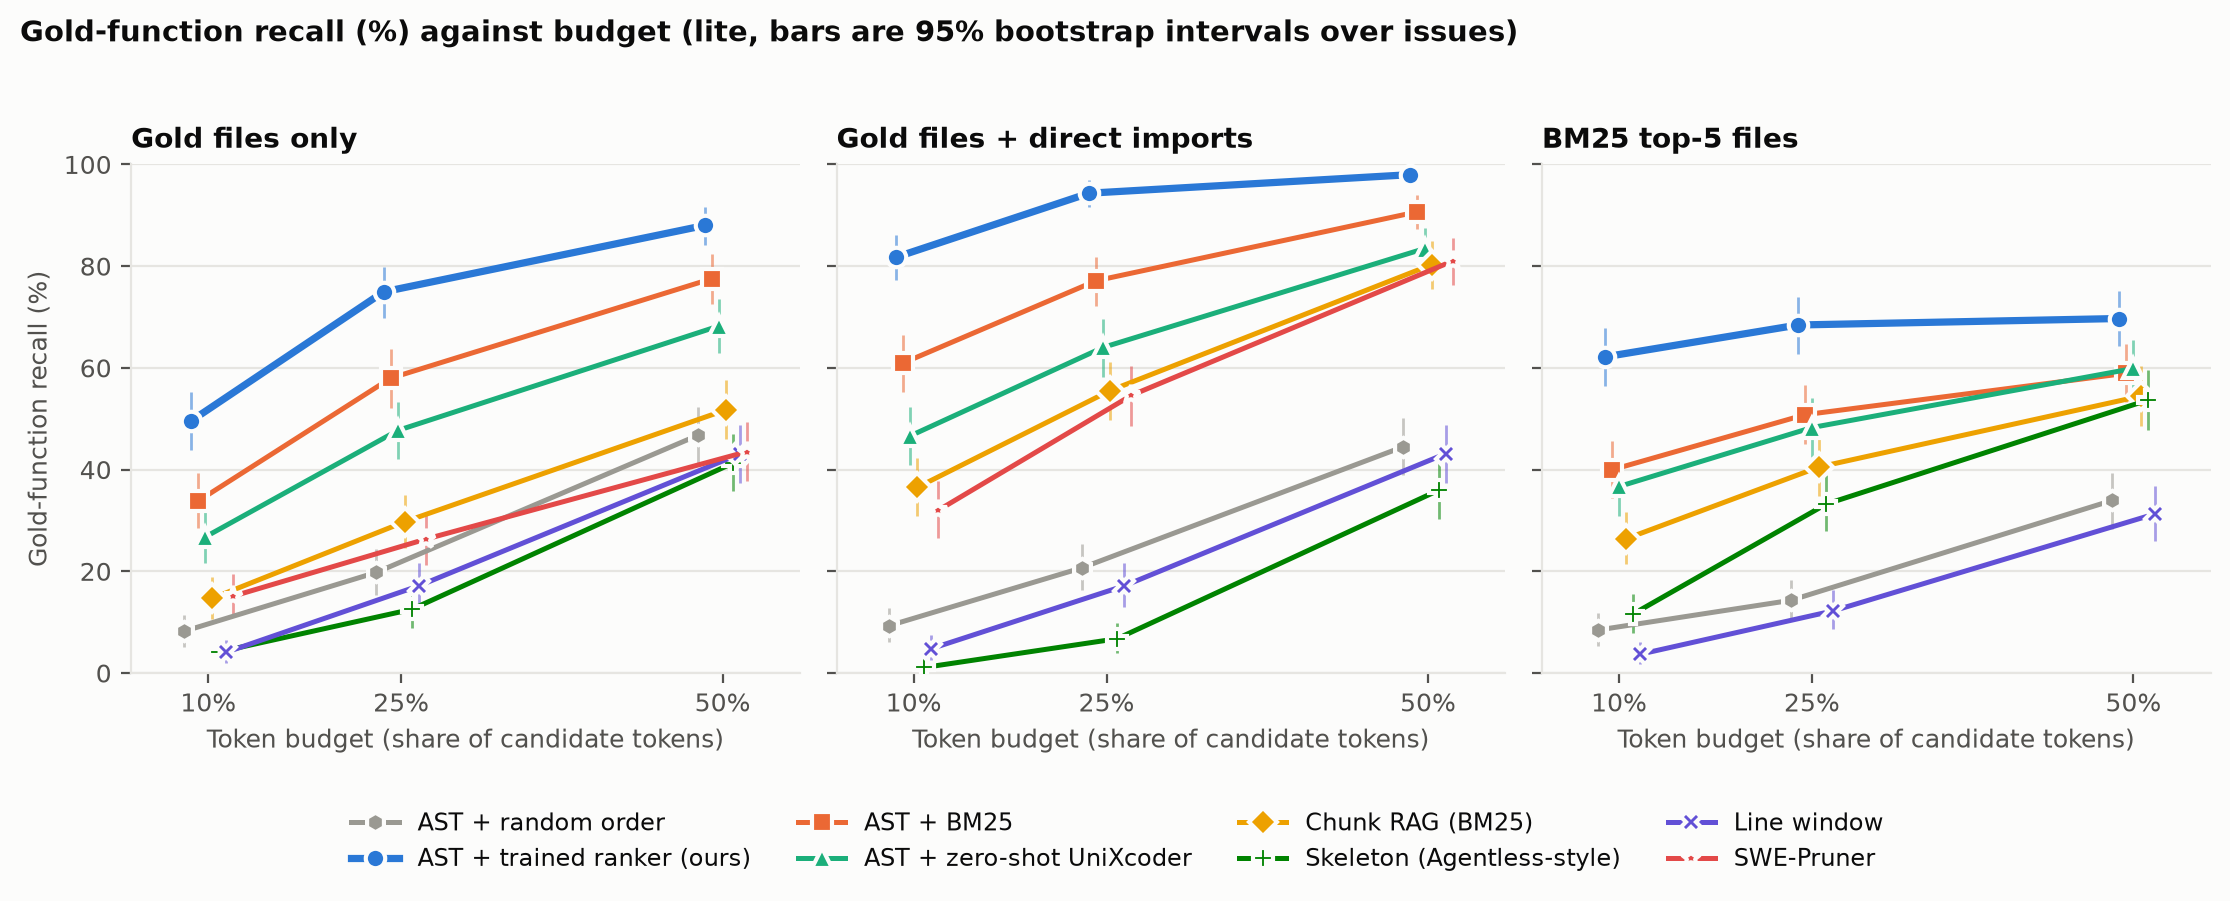

In [3]:
display(Markdown((ROOT / "results/tables/lite_oracle_imports_main.md").read_text()))
display(Image(str(ROOT / "results/figures/lite_recall_vs_budget.png")))

## 3. Is the difference real? Paired bootstrap over issues

Paired bootstrap differences in gold-function recall, lite, gold files + direct imports.

| Question | A | B | Budget | A minus B (pp) | 95% interval | p | Issues |
|---|---|---|---|---|---|---|---|
| H1 | AST + BM25 | Line window | 10% | +56.1 | [+49.6, +62.7] | <0.001 | 274 |
| H1 | AST + BM25 | Line window | 25% | +60.0 | [+53.3, +66.4] | <0.001 | 274 |
| H1 | AST + BM25 | Line window | 50% | +47.6 | [+40.8, +54.3] | <0.001 | 274 |
| H1 | AST + BM25 | Line window | 1000 tok | +40.3 | [+34.5, +46.2] | <0.001 | 271 |
| H1 | AST + BM25 | Line window | 2000 tok | +49.6 | [+43.5, +55.6] | <0.001 | 268 |
| H1 | AST + BM25 | Line window | 4000 tok | +54.1 | [+47.6, +60.5] | <0.001 | 262 |
| H1 | AST + BM25 | Chunk RAG (BM25) | 10% | +24.5 | [+18.5, +30.6] | <0.001 | 274 |
| H1 | AST + BM25 | Chunk RAG (BM25) | 25% | +21.6 | [+15.9, +27.5] | <0.001 | 274 |
| H1 | AST + BM25 | Chunk RAG (BM25) | 50% | +10.4 | [+5.7, +15.3] | <0.001 | 274 |
| H1 | AST + BM25 | Chunk RAG (BM25) | 1000 tok | +21.6 | [+16.0, +27.4] | <0.001 | 271 |
| H1 | AST + BM25 | Chunk RAG (BM25) | 2000 tok | +27.0 | [+21.1, +33.1] | <0.001 | 268 |
| H1 | AST + BM25 | Chunk RAG (BM25) | 4000 tok | +21.4 | [+15.8, +27.0] | <0.001 | 262 |
| H1 | AST + UniXcoder, zero-shot | Chunk RAG (UniXcoder, zero-shot) | 10% | +24.2 | [+18.2, +30.1] | <0.001 | 274 |
| H1 | AST + UniXcoder, zero-shot | Chunk RAG (UniXcoder, zero-shot) | 25% | +17.2 | [+11.7, +23.0] | <0.001 | 274 |
| H1 | AST + UniXcoder, zero-shot | Chunk RAG (UniXcoder, zero-shot) | 50% | +13.7 | [+8.2, +19.1] | <0.001 | 274 |
| H1 | AST + UniXcoder, zero-shot | Chunk RAG (UniXcoder, zero-shot) | 1000 tok | +14.9 | [+10.1, +19.6] | <0.001 | 271 |
| H1 | AST + UniXcoder, zero-shot | Chunk RAG (UniXcoder, zero-shot) | 2000 tok | +17.0 | [+11.7, +22.4] | <0.001 | 268 |
| H1 | AST + UniXcoder, zero-shot | Chunk RAG (UniXcoder, zero-shot) | 4000 tok | +18.7 | [+13.2, +24.3] | <0.001 | 262 |
| H2 | AST + trained ranker (ours) | AST + UniXcoder, zero-shot | 10% | +35.1 | [+29.3, +41.0] | <0.001 | 274 |
| H2 | AST + trained ranker (ours) | AST + UniXcoder, zero-shot | 25% | +30.3 | [+24.8, +36.0] | <0.001 | 274 |
| H2 | AST + trained ranker (ours) | AST + UniXcoder, zero-shot | 50% | +14.5 | [+10.5, +18.8] | <0.001 | 274 |
| H2 | AST + trained ranker (ours) | AST + UniXcoder, zero-shot | 1000 tok | +32.1 | [+26.4, +38.0] | <0.001 | 271 |
| H2 | AST + trained ranker (ours) | AST + UniXcoder, zero-shot | 2000 tok | +36.4 | [+30.3, +42.5] | <0.001 | 268 |
| H2 | AST + trained ranker (ours) | AST + UniXcoder, zero-shot | 4000 tok | +36.8 | [+30.9, +42.7] | <0.001 | 262 |
| H2 | AST + trained ranker (ours) | AST + BM25 | 10% | +20.8 | [+14.8, +26.9] | <0.001 | 274 |
| H2 | AST + trained ranker (ours) | AST + BM25 | 25% | +17.2 | [+12.4, +22.1] | <0.001 | 274 |
| H2 | AST + trained ranker (ours) | AST + BM25 | 50% | +7.3 | [+4.2, +10.6] | <0.001 | 274 |
| H2 | AST + trained ranker (ours) | AST + BM25 | 1000 tok | +18.1 | [+12.0, +24.1] | <0.001 | 271 |
| H2 | AST + trained ranker (ours) | AST + BM25 | 2000 tok | +19.5 | [+13.2, +25.8] | <0.001 | 268 |
| H2 | AST + trained ranker (ours) | AST + BM25 | 4000 tok | +23.3 | [+17.3, +29.3] | <0.001 | 262 |
| H2 | AST + trained ranker + BM25 (ours) | AST + BM25 | 10% | +18.6 | [+13.7, +23.5] | <0.001 | 274 |
| H2 | AST + trained ranker + BM25 (ours) | AST + BM25 | 25% | +15.8 | [+11.7, +20.1] | <0.001 | 274 |
| H2 | AST + trained ranker + BM25 (ours) | AST + BM25 | 50% | +6.9 | [+4.2, +9.9] | <0.001 | 274 |
| H2 | AST + trained ranker + BM25 (ours) | AST + BM25 | 1000 tok | +17.2 | [+12.0, +22.4] | <0.001 | 271 |
| H2 | AST + trained ranker + BM25 (ours) | AST + BM25 | 2000 tok | +16.7 | [+11.6, +22.1] | <0.001 | 268 |
| H2 | AST + trained ranker + BM25 (ours) | AST + BM25 | 4000 tok | +18.2 | [+13.1, +23.3] | <0.001 | 262 |
| H2 | AST + trained ranker (ours) | AST + LLM perplexity | 10% | +11.4 | [+6.2, +16.5] | <0.001 | 274 |
| H2 | AST + trained ranker (ours) | AST + LLM perplexity | 25% | +12.2 | [+7.7, +16.8] | <0.001 | 274 |
| H2 | AST + trained ranker (ours) | AST + LLM perplexity | 50% | +8.0 | [+4.9, +11.3] | <0.001 | 274 |
| H2 | AST + trained ranker (ours) | AST + LLM perplexity | 1000 tok | +6.6 | [+0.9, +12.1] | 0.021 | 271 |
| H2 | AST + trained ranker (ours) | AST + LLM perplexity | 2000 tok | +8.6 | [+3.4, +13.9] | 0.001 | 268 |
| H2 | AST + trained ranker (ours) | AST + LLM perplexity | 4000 tok | +12.6 | [+7.7, +17.6] | <0.001 | 262 |
| external | AST + trained ranker (ours) | SWE-Pruner (released checkpoint) | 10% | +49.7 | [+43.4, +55.8] | <0.001 | 274 |
| external | AST + trained ranker (ours) | SWE-Pruner (released checkpoint) | 25% | +39.8 | [+33.9, +45.7] | <0.001 | 274 |
| external | AST + trained ranker (ours) | SWE-Pruner (released checkpoint) | 50% | +17.0 | [+12.6, +21.5] | <0.001 | 274 |
| external | AST + trained ranker (ours) | SWE-Pruner (released checkpoint) | 1000 tok | +39.3 | [+33.1, +45.4] | <0.001 | 271 |
| external | AST + trained ranker (ours) | SWE-Pruner (released checkpoint) | 2000 tok | +45.7 | [+39.4, +52.0] | <0.001 | 268 |
| external | AST + trained ranker (ours) | SWE-Pruner (released checkpoint) | 4000 tok | +47.1 | [+41.0, +53.2] | <0.001 | 262 |


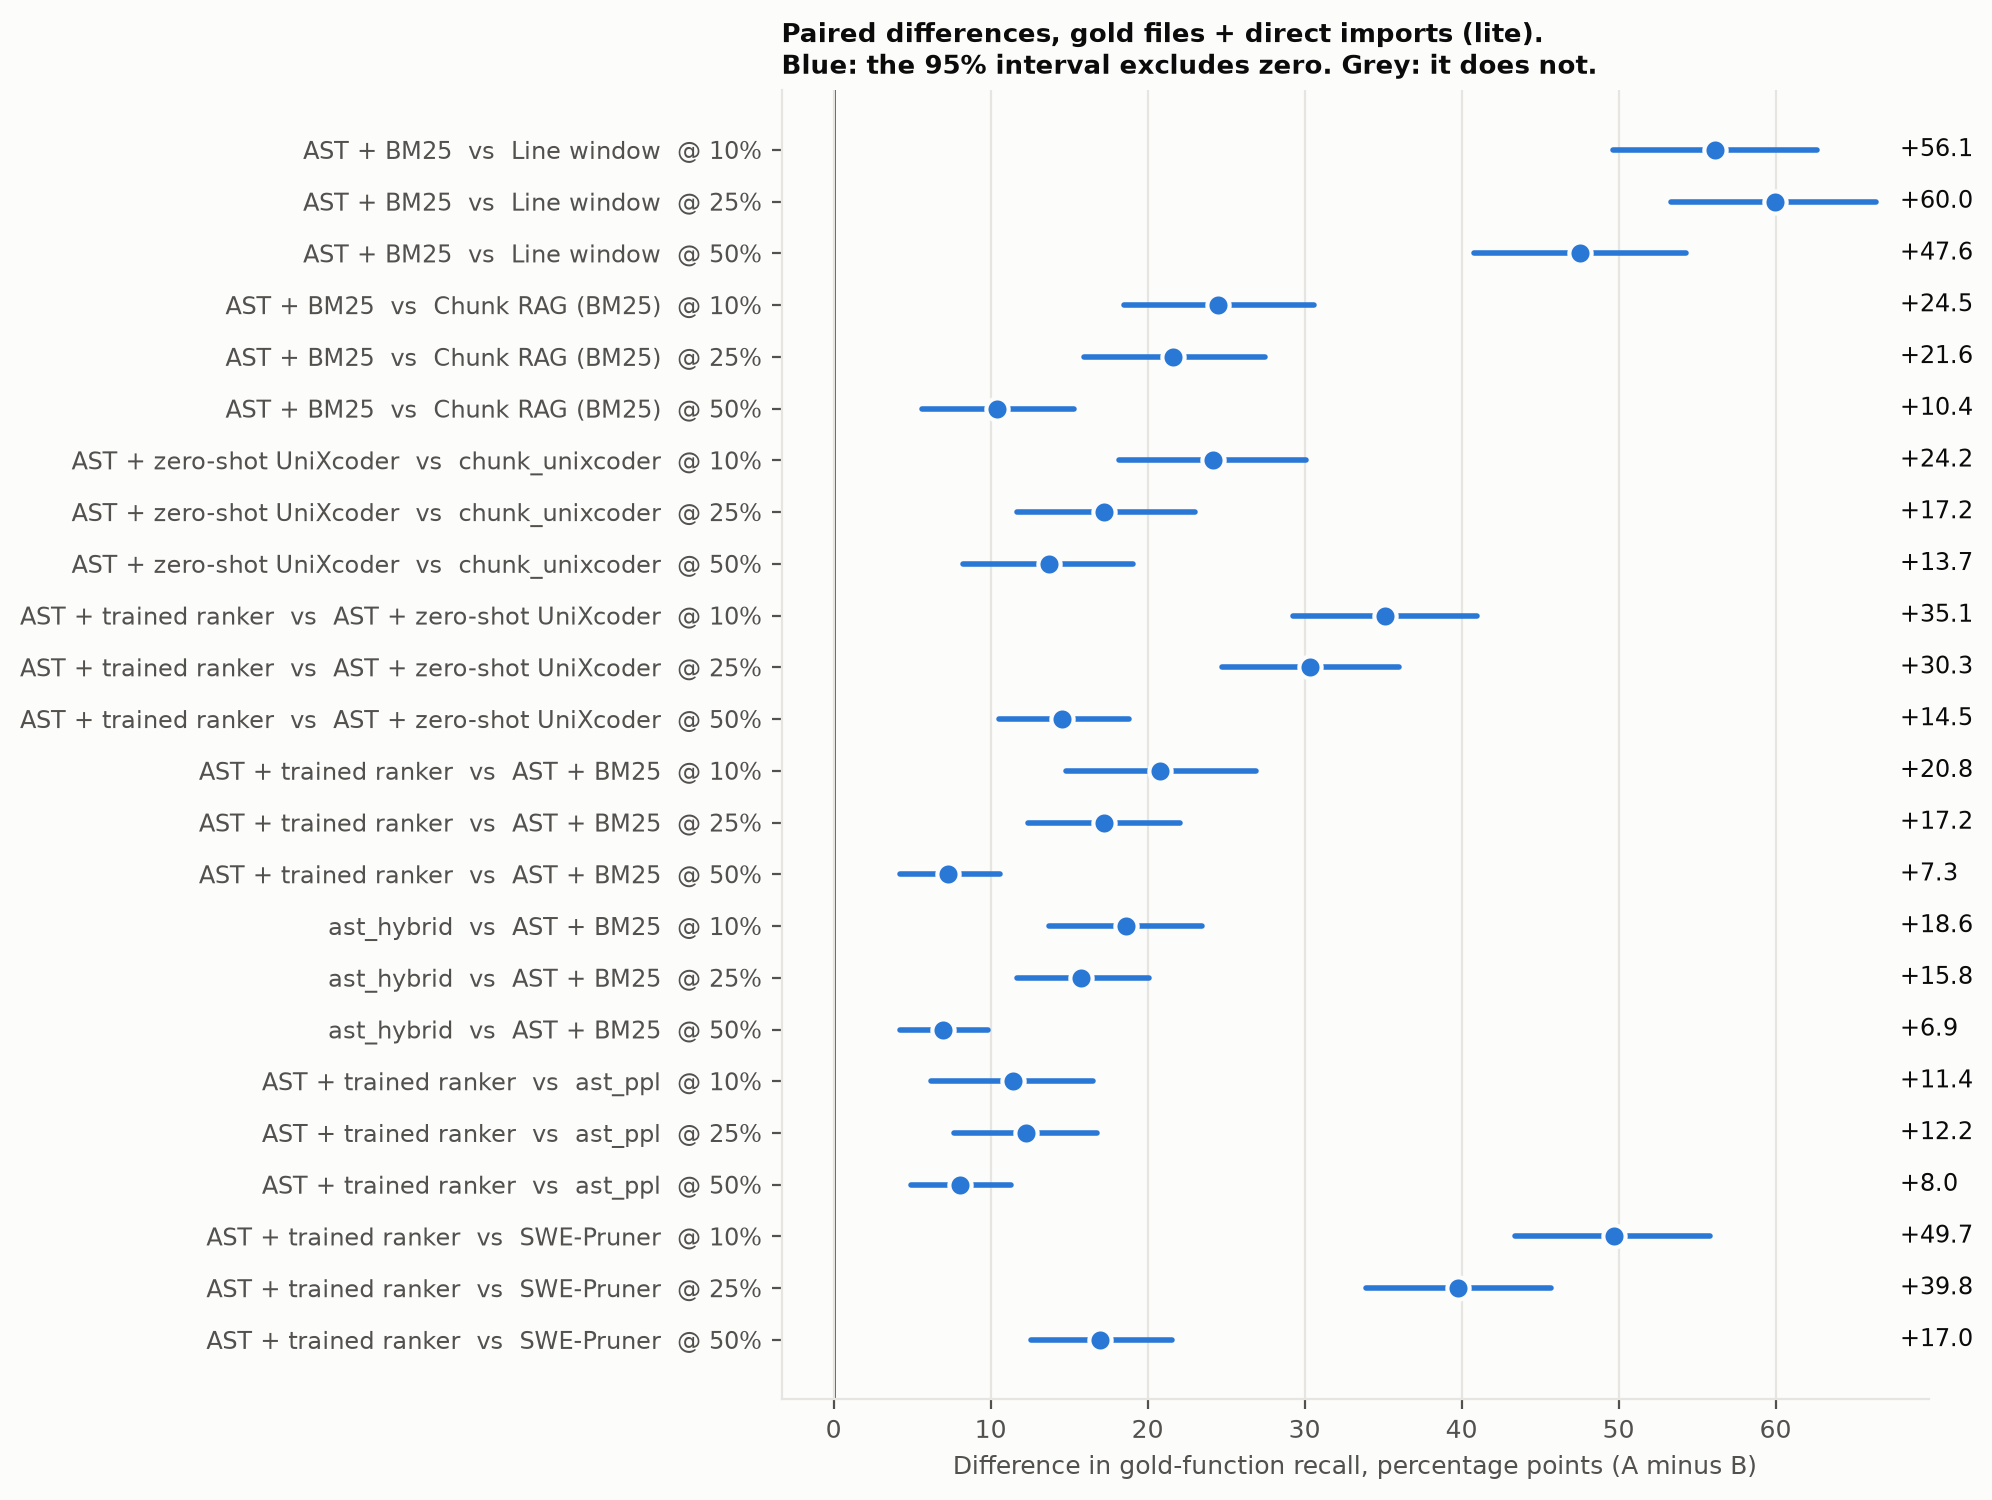

In [4]:
display(Markdown((ROOT / "results/tables/lite_oracle_imports_paired.md").read_text()))
display(Image(str(ROOT / "results/figures/lite_paired_differences.png")))

## 4. The granularity-neutral view: gold-line recall

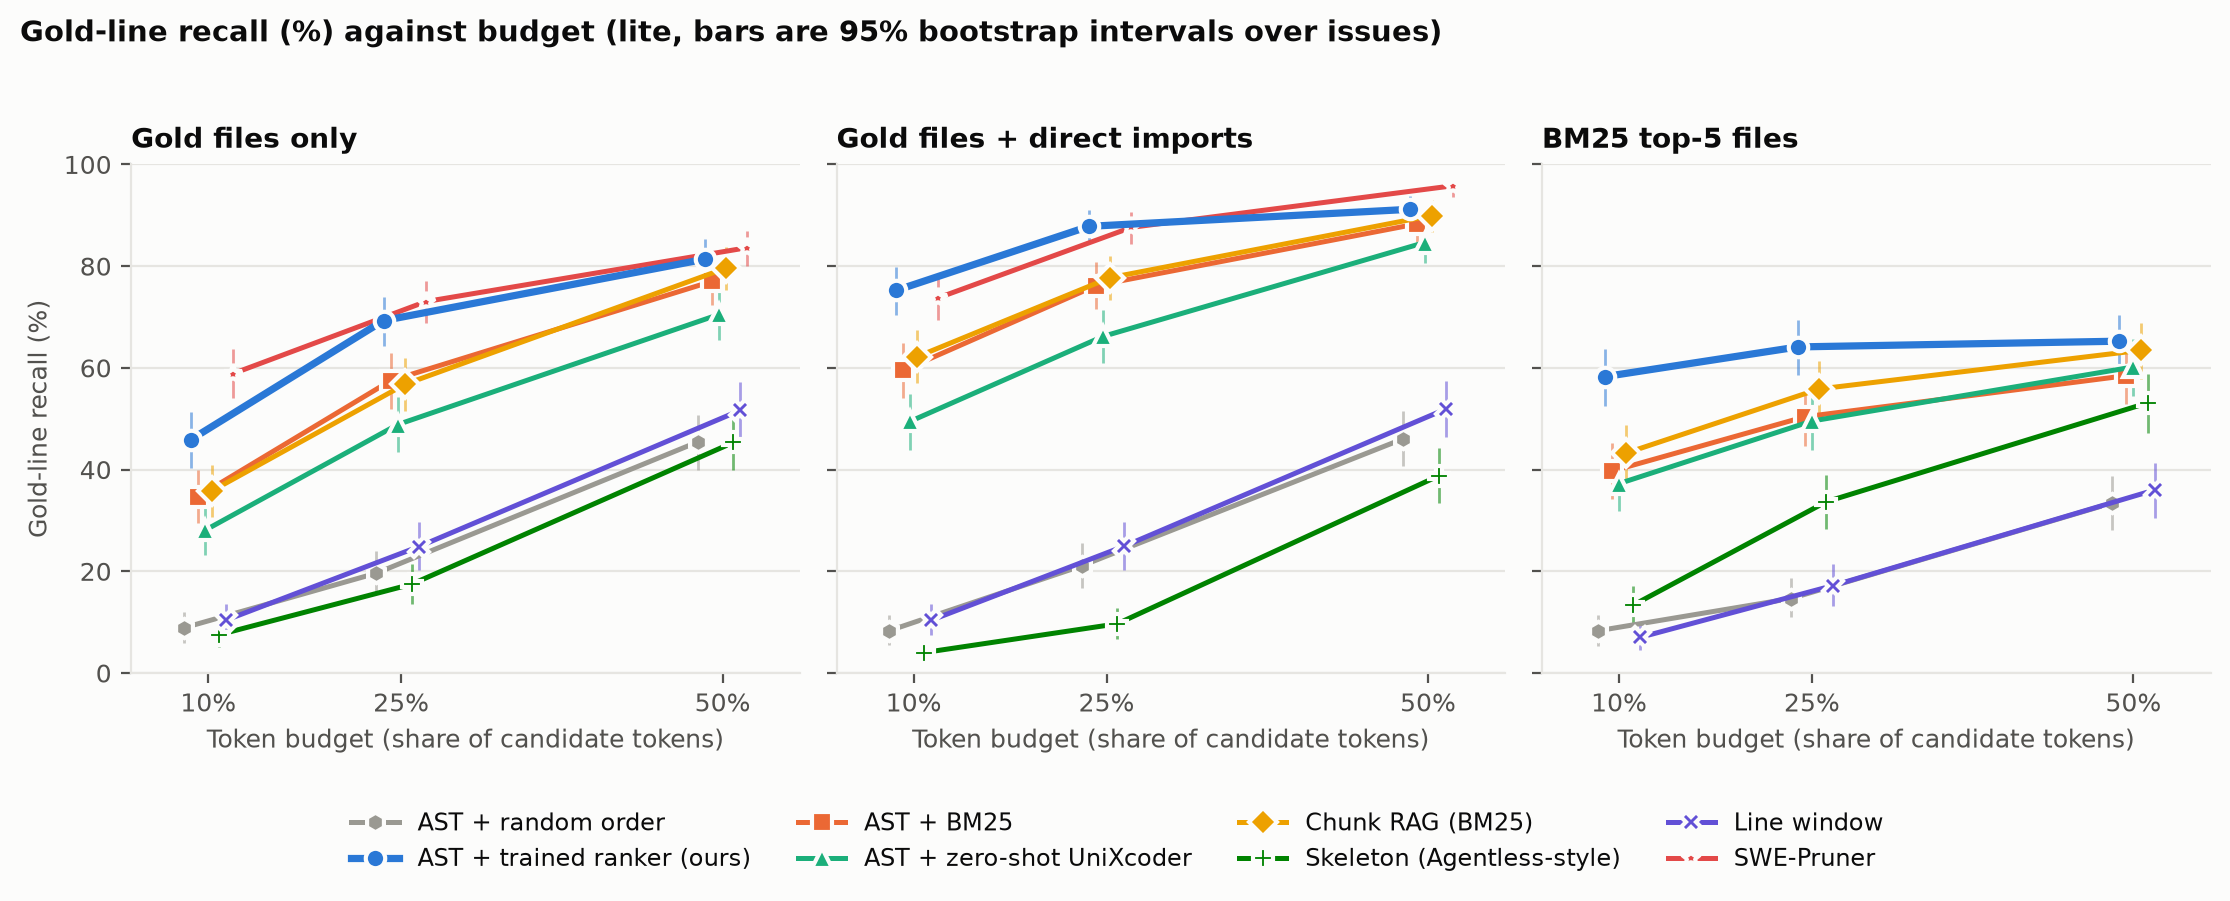

In [5]:
display(Image(str(ROOT / "results/figures/lite_line_recall_vs_budget.png")))

## 5. Second test set: SWE-bench Verified

In [6]:
display(Markdown((ROOT / "results/tables/verified_oracle_imports_main.md").read_text()))

Gold-function recall with 95% bootstrap intervals and other metrics, in percent. verified, gold files + direct imports, 458 issues with a gold function.

| Method | Recall @10% | Recall @25% | Recall @50% | Line recall @25% | All-gold @25% | Sig. recall @25% | Precision @25% | Parses @25% |
|---|---|---|---|---|---|---|---|---|
| Line window | 4.9 [3.1, 6.8] | 17.0 [13.8, 20.3] | 45.8 [41.5, 50.1] | 23.2 | 13.3 | 26.7 | 1.9 | 42.2 |
| Chunk RAG (BM25) | 32.3 [28.2, 36.5] | 54.2 [49.7, 58.5] | 74.7 [70.8, 78.3] | 75.3 | 48.5 | 73.2 | 6.0 | 11.7 |
| Chunk RAG (UniXcoder, zero-shot) | 24.5 [20.8, 28.4] | 44.5 [40.2, 48.8] | 67.3 [63.3, 71.3] | 67.4 | 39.3 | 61.4 | 5.6 | 15.6 |
| Skeleton (Agentless-style) | 0.4 [0.0, 1.0] | 8.7 [6.3, 11.3] | 40.0 [35.7, 44.3] | 12.9 | 7.2 | 98.0 | 1.1 | 100.0 |
| AST + random order | 7.2 [5.2, 9.4] | 21.6 [18.2, 25.1] | 49.1 [44.9, 53.3] | 22.0 | 15.5 | 26.9 | 1.9 | 100.0 |
| AST + BM25 | 56.5 [52.1, 60.9] | 73.7 [69.8, 77.4] | 86.8 [83.8, 89.5] | 72.9 | 68.6 | 76.5 | 6.8 | 100.0 |
| AST + UniXcoder, zero-shot | 46.8 [42.5, 51.3] | 66.9 [62.9, 70.9] | 83.2 [79.9, 86.4] | 69.1 | 61.4 | 70.6 | 5.4 | 100.0 |
| AST + trained ranker (ours) | 83.2 [79.9, 86.3] | 92.8 [90.6, 94.8] | 98.1 [97.0, 99.0] | 87.0 | 88.6 | 94.6 | 7.6 | 100.0 |
| AST + trained ranker + BM25 (ours) | 78.5 [75.0, 81.9] | 91.4 [88.9, 93.5] | 96.1 [94.5, 97.5] | 86.6 | 87.3 | 92.4 | 7.8 | 100.0 |


## 6. Every candidate-file setting at a 25% budget

In [7]:
for split in ("lite", "verified"):
    display(Markdown((ROOT / f"results/tables/{split}_settings.md").read_text()))

Gold-function recall (%) at a 25% budget under each candidate-file setting, lite.

| Method | Gold files only | Gold files + direct imports | BM25 top-5 files | BM25 top-10 files | BM25 top-20 files |
|---|---|---|---|---|---|
| Line window | 17.2 | 17.2 | 12.2 | 14.4 | 15.9 |
| Chunk RAG (BM25) | 29.7 | 55.5 | 40.5 | 48.8 | 59.7 |
| Chunk RAG (UniXcoder, zero-shot) | 19.3 | 46.8 | 32.2 | n/a | n/a |
| Skeleton (Agentless-style) | 12.5 | 6.8 | 33.2 | 43.4 | 54.2 |
| SWE-Pruner (released checkpoint) | 26.3 | 54.6 | n/a | n/a | n/a |
| AST + random order | 19.8 | 20.7 | 14.3 | 17.8 | 18.9 |
| AST + BM25 | 58.0 | 77.1 | 50.8 | 60.3 | 67.1 |
| AST + UniXcoder, zero-shot | 47.7 | 64.0 | 48.3 | 54.3 | 61.3 |
| AST + LLM perplexity | 63.0 | 82.1 | n/a | n/a | n/a |
| AST + trained ranker (ours) | 74.9 | 94.3 | 68.4 | 76.1 | 83.4 |
| AST + trained ranker + BM25 (ours) | 73.5 | 92.9 | 66.7 | 75.4 | 82.5 |


Gold-function recall (%) at a 25% budget under each candidate-file setting, verified.

| Method | Gold files only | Gold files + direct imports | BM25 top-5 files | BM25 top-10 files | BM25 top-20 files |
|---|---|---|---|---|---|
| Line window | 16.7 | 17.0 | 13.1 | 14.5 | 15.6 |
| Chunk RAG (BM25) | 27.9 | 54.2 | 33.4 | 43.2 | 55.8 |
| Chunk RAG (UniXcoder, zero-shot) | 22.8 | 44.5 | 30.9 | n/a | n/a |
| Skeleton (Agentless-style) | 13.3 | 8.7 | 29.9 | 41.2 | 50.7 |
| AST + random order | 21.5 | 21.6 | 15.6 | 18.9 | 21.1 |
| AST + BM25 | 53.7 | 73.7 | 49.3 | 59.0 | 67.3 |
| AST + UniXcoder, zero-shot | 48.1 | 66.9 | 46.1 | 52.7 | 61.9 |
| AST + trained ranker (ours) | 73.2 | 92.8 | 63.7 | 74.9 | 83.7 |
| AST + trained ranker + BM25 (ours) | 69.1 | 91.4 | 61.4 | 73.1 | 82.6 |


## 7. Selector ablations

In [8]:
display(Markdown((ROOT / "results/tables/lite_oracle_imports_ablation.md").read_text()))

Selector ablations (%), lite, gold files + direct imports.

| Selector | Recall @10% | Recall @25% | Recall @50% | Sig. recall @10% | Sig. recall @25% | Line recall @25% |
|---|---|---|---|---|---|---|
| AST + BM25 | 60.9 | 77.1 | 90.7 | 67.2 | 81.5 | 76.2 |
| AST + BM25, no signature tier | 60.9 | 77.9 | 91.2 | 60.9 | 77.9 | 76.9 |
| AST + trained ranker (ours) | 81.8 | 94.3 | 98.0 | 87.6 | 95.4 | 87.8 |
| AST + trained ranker (ours), rank by probability per token | 79.0 | 90.9 | 98.0 | 86.9 | 94.0 | 84.7 |
| AST + trained ranker (ours), no signature tier | 81.8 | 94.7 | 98.0 | 81.8 | 94.7 | 88.6 |
| AST + trained ranker (ours), budget split per file | 49.5 | 74.9 | 88.0 | 68.5 | 88.6 | 69.3 |
| AST + trained ranker (ours), 15% of budget reserved for signatures | 80.1 | 92.2 | 97.1 | 94.3 | 98.4 | 85.4 |
| AST + trained ranker (ours), 30% of budget reserved for signatures | 78.1 | 92.2 | 97.1 | 96.5 | 99.6 | 85.5 |
| AST + trained ranker + BM25 (ours) | 79.6 | 92.9 | 97.6 | 84.1 | 93.6 | 87.0 |


## 8. Per-repository breakdown (computed here from the raw rows)

In [9]:
def per_repo(split, setting, methods, budget="r0.25"):
    frames = []
    for m in methods:
        path = ROOT / f"results/runs/{split}/{setting}/{m}.jsonl"
        if path.exists():
            frames.append(pd.read_json(path, lines=True).query("budget == @budget").assign(method=m))
    df = pd.concat(frames).dropna(subset=["gold_fn_recall"])
    table = df.pivot_table(index="repo", columns="method", values="gold_fn_recall", aggfunc="mean") * 100
    table["issues"] = df[df.method == methods[0]].groupby("repo").size()
    return table.round(1)

per_repo("lite", "oracle_imports", ["ast_trained", "ast_bm25", "ast_unixcoder", "chunk_bm25"])

method,ast_bm25,ast_trained,ast_unixcoder,chunk_bm25,issues
repo,,,,,
astropy/astropy,75.0,91.7,58.3,66.7,6
django/django,87.1,96.6,76.6,59.8,102
matplotlib/matplotlib,84.1,95.5,54.2,72.7,22
mwaskom/seaborn,50.0,100.0,75.0,50.0,4
pallets/flask,83.3,100.0,83.3,50.0,3
psf/requests,83.3,100.0,66.7,50.0,6
pydata/xarray,40.0,80.0,40.0,60.0,5
pylint-dev/pylint,66.7,83.3,0.0,50.0,6
pytest-dev/pytest,68.8,100.0,43.8,25.0,16


## 9. Training curve, scaling and error categories

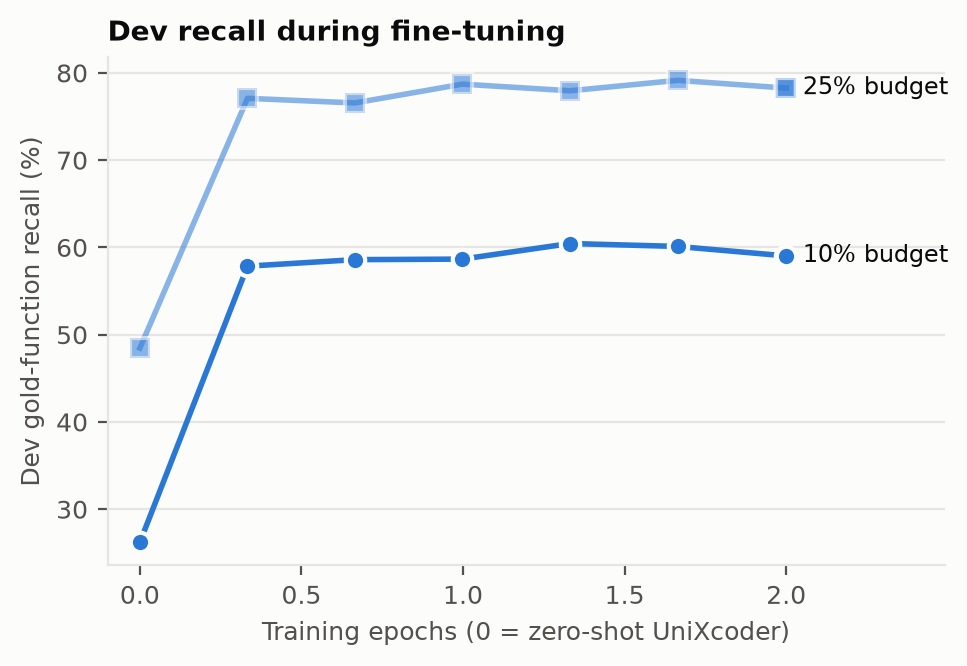

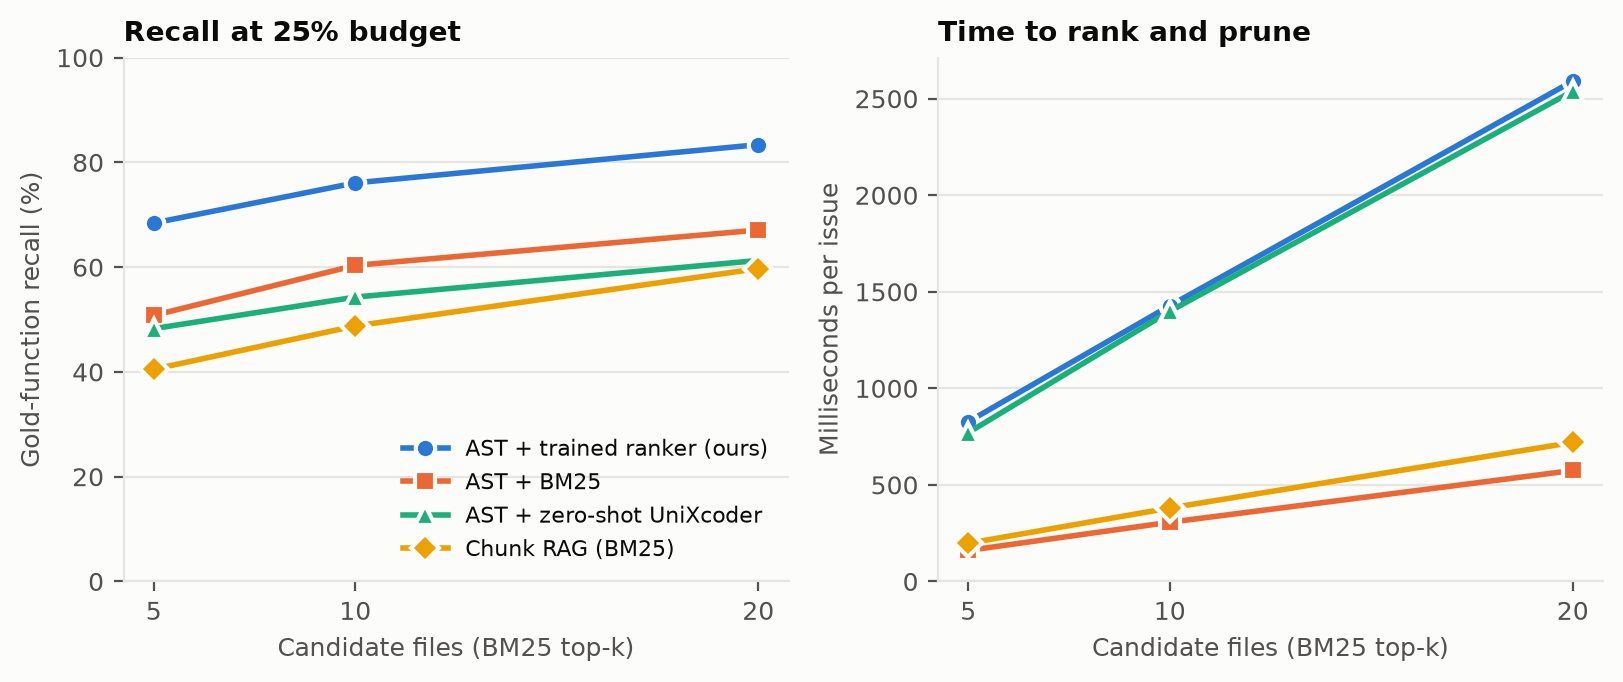

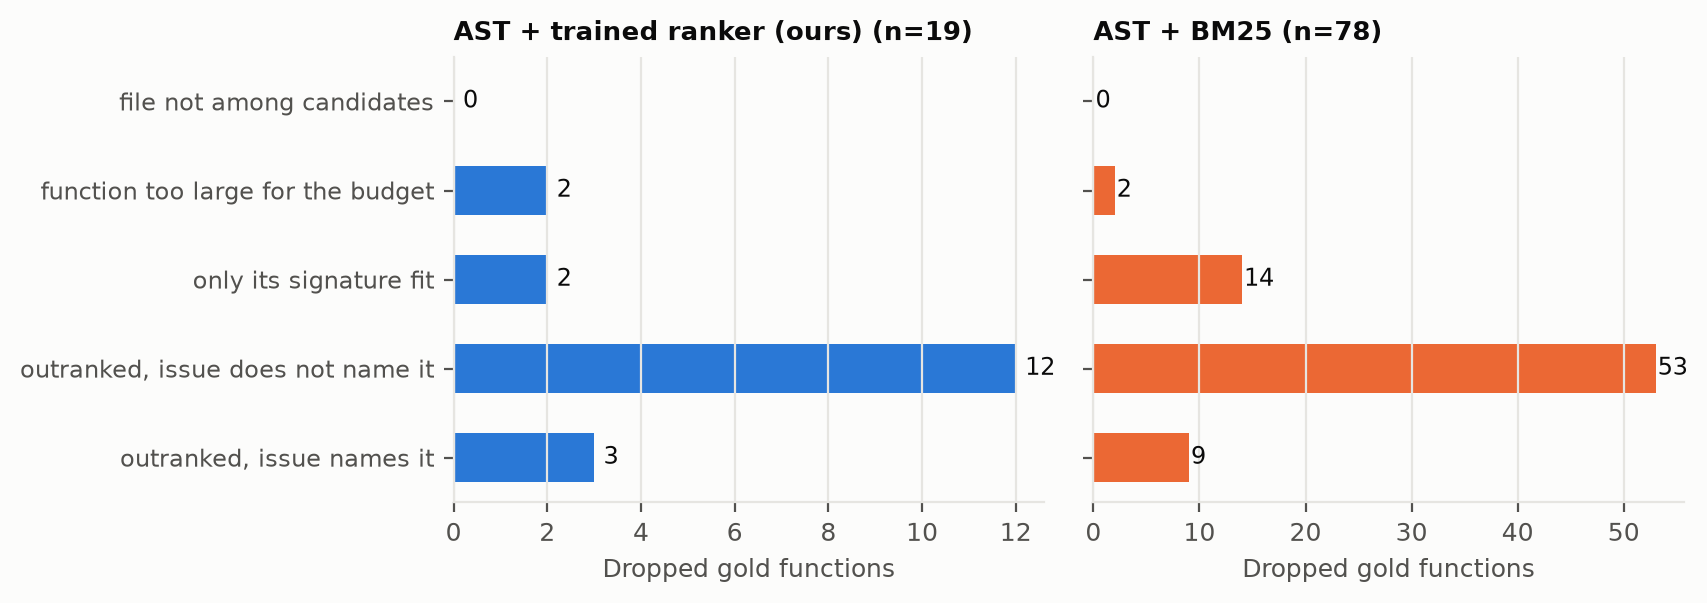

In [10]:
for name in ("training_dev_recall", "lite_scaling", "error_categories"):
    path = ROOT / f"results/figures/{name}.png"
    if path.exists():
        display(Image(str(path)))
    else:
        print("not built yet:", path.name)